# Dataset Analysis - Racial Bias

In [17]:
!pip install datasets pandas


In [18]:
pip install datasets pandas


Note: you may need to restart the kernel to use updated packages.


In [1]:
from datasets import load_dataset

ds = load_dataset("mediabiasgroup/mbib-base")
racial_ds = ds["racial_bias"]

df = racial_ds.to_pandas()

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


In [2]:
import os

# Print the names of the files inside the 'data' directory
print("Files inside 'data' directory:", os.listdir("data"))

Files inside 'data' directory: ['mbib_base_cognitive_bias.csv', 'mbib_base_fake_news.csv', 'mbib_base_gender_bias.csv', 'mbib_base_hate_speech.csv', 'mbib_base_linguistic_bias.csv', 'mbib_base_political_bias.csv', 'mbib_base_racial_bias.csv', 'mbib_base_text_level_bias.csv']


##  Loading and Inspecting Racial Bias Dataset

In [3]:
import os
import pandas as pd

# 1. Define the path to the racial bias CSV file
file_path = os.path.join("data", "mbib_base_racial_bias.csv")

# 2. Read the CSV file into a pandas DataFrame
df_racial = pd.read_csv(file_path)

# 3. Print dataset dimensions and column names
print(f"Total number of rows: {len(df_racial)}")
print(f"Columns available: {list(df_racial.columns)}")

# 4. Display the first 5 rows to inspect the data
display(df_racial.head())

Total number of rows: 9788
Columns available: ['id', 'text', 'label', 'dataset_id']


,id,text,label,dataset_id
0,075-228,nah fam any art of best girl is good art,0,75
1,075-121,flaming neko girl is best girl easy amp b fant...,0,75
2,075-2476,similar motive where bush came out and said mu...,0,75
3,075-1447,no fuck that religion as an excuse shit they a...,0,75
4,075-2257,so you believe ex muslims are vile criminals,0,75


/tmp/ipykernel_3650/1549891764.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_racial, x="label", palette="Blues_d")


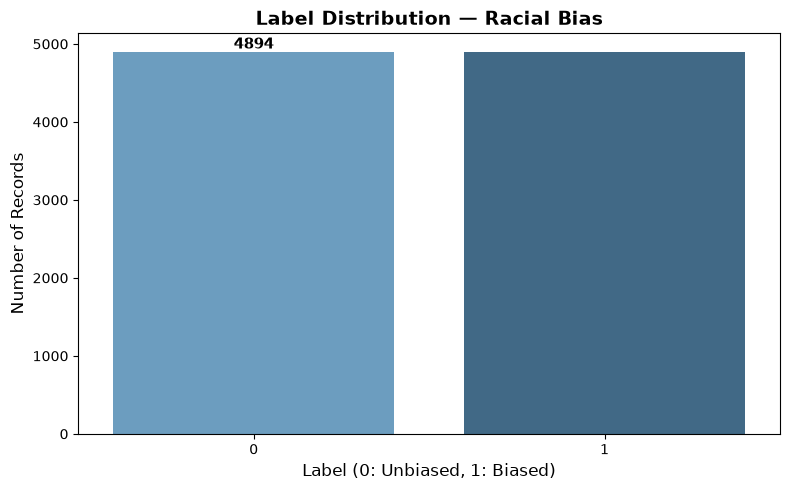

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df_racial, x="label", palette="Blues_d")

plt.title("Label Distribution — Racial Bias", fontsize=14, fontweight='bold')
plt.xlabel("Label (0: Unbiased, 1: Biased)", fontsize=12)
plt.ylabel("Number of Records", fontsize=12)

ax.bar_label(ax.containers[0], fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

### 📊 Figure Insights: Label Distribution
- **Observation:** The dataset exhibits a **perfect 50/50 balance** between the two classes.
- **Breakdown:** 
  - **Label 0 (Unbiased / Neutral):** 4,894 samples.
  - **Label 1 (Biased):** 4,894 samples.
- **Implication:** This balanced distribution ensures that our models will not suffer from class imbalance issues during training, making **Accuracy** and **Macro F1-Score** reliable metrics for evaluation.

##  Dataset and Labels Exploration

In [5]:
import pandas as pd

# 1. Count examples in each class (label)
print("--- 1. Class Distribution ---")
class_counts = df_racial['label'].value_counts()
print(class_counts)
print("\nClass Distribution (Percentage):")
print(df_racial['label'].value_counts(normalize=True) * 100)

# 2. Record the source and count of examples in each source/dataset_id
print("\n--- 2. Sources Distribution (dataset_id) ---")
source_counts = df_racial['dataset_id'].value_counts()
print(source_counts)

# 3. Check for duplicates in texts
print("\n--- 3. Duplicates Check ---")
duplicates_count = df_racial['text'].duplicated().sum()
print(f"Number of duplicate texts: {duplicates_count}")

# 4. Read examples from every class (Short and Long texts)
print("\n--- 4. Reading Examples from Each Class ---")
# Add text length column to help find short and long examples
df_racial['text_length'] = df_racial['text'].astype(str).apply(len)

for label in df_racial['label'].unique():
    print(f"\n================ Class: {label} ================")
    class_subset = df_racial[df_racial['label'] == label]

    # Shortest text example
    shortest_row = class_subset.loc[class_subset['text_length'].idxmin()]
    print(f"-> Shortest text (Length: {shortest_row['text_length']}):")
    print(f"   \"{shortest_row['text']}\"")

    # Longest text example
    longest_row = class_subset.loc[class_subset['text_length'].idxmax()]
    print(f"-> Longest text (Length: {longest_row['text_length']}):")
    print(f"   \"{longest_row['text']}\"")

--- 1. Class Distribution ---
label
0    4894
1    4894
Name: count, dtype: int64

Class Distribution (Percentage):
label
0    50.0
1    50.0
Name: proportion, dtype: float64

--- 2. Sources Distribution (dataset_id) ---
dataset_id
75     9335
110     453
Name: count, dtype: int64

--- 3. Duplicates Check ---
Number of duplicate texts: 0

--- 4. Reading Examples from Each Class ---

================ Class: 0 ================
-> Shortest text (Length: 13):
   "ur mom is art"
-> Longest text (Length: 198):
   "meanwhile jokes about killing immigrants black people and jews are all over reddits right wing political and conspiracy subs seems like you prioritize your whining based on your own political biases"

================ Class: 1 ================
-> Shortest text (Length: 3):
   "Gay"
-> Longest text (Length: 199):
   "yeah though its still a bit of an oof that the race he says are similar to jews are the ones who succumb easiest to greed and literally mine so greedily and so deep tha

##  Text Exploration

In [6]:
import pandas as pd
import numpy as np
import re
from collections import Counter

# 1. Text Length Analysis (Characters and Words)
df_racial['word_count'] = df_racial['text'].astype(str).apply(lambda x: len(x.split()))
df_racial['char_count'] = df_racial['text'].astype(str).apply(len)

print("--- 1. Text Length Comparison Across Labels ---")
length_summary = df_racial.groupby('label')[['word_count', 'char_count']].agg(['mean', 'median', 'std', 'min', 'max'])
display(length_summary)

# 2. Check for URLs, Emojis/Special Characters, and Punctuation
print("\n--- 2. Presence of URLs, Special Characters, and Punctuation ---")
url_pattern = r'https?://\S+|www\.\S+'
special_char_pattern = r'[^\w\s]'

df_racial['has_url'] = df_racial['text'].astype(str).apply(lambda x: bool(re.search(url_pattern, x)))
df_racial['has_special_chars'] = df_racial['text'].astype(str).apply(lambda x: bool(re.search(special_char_pattern, x)))

url_counts = df_racial.groupby('label')['has_url'].value_counts(normalize=True) * 100
print("Percentage of texts with URLs by label:")
print(url_counts)

special_char_counts = df_racial.groupby('label')['has_special_chars'].value_counts(normalize=True) * 100
print("\nPercentage of texts with Special Characters/Punctuation by label:")
print(special_char_counts)

# 3. Top Common Words per Class (Excluding Basic Stopwords)
print("\n--- 3. Top Common Words per Class ---")
basic_stopwords = {'the', 'a', 'an', 'in', 'on', 'at', 'of', 'for', 'to', 'is', 'are', 'was', 'were', 'and', 'or', 'it', 'that', 'this', 'you', 'i', 'my', 'with', 'be', 'as', 'they', 'have', 'but'}

for label in sorted(df_racial['label'].unique()):
    text_corpus = " ".join(df_racial[df_racial['label'] == label]['text'].astype(str).str.lower())
    words = [re.sub(r'[^\w]', '', w) for w in text_corpus.split()]
    filtered_words = [w for w in words if w and w not in basic_stopwords]

    most_common = Counter(filtered_words).most_common(10)
    print(f"\nTop 10 Most Common Words in Label {label}:")
    for word, count in most_common:
        print(f"  {word}: {count}")

--- 1. Text Length Comparison Across Labels ---


word_count                           char_count                        \
            mean median       std min max        mean median        std min   
label                                                                         
0      19.100123   19.0  6.900225   3  41  103.541071  105.0  37.577076  13   
1      16.749285   16.5  7.104651   1  40   89.683899   89.0  37.794728   3   

            
       max  
label       
0      198  
1      199


--- 2. Presence of URLs, Special Characters, and Punctuation ---
Percentage of texts with URLs by label:
label  has_url
0      False      100.0
1      False      100.0
Name: proportion, dtype: float64

Percentage of texts with Special Characters/Punctuation by label:
label  has_special_chars
0      False                100.0
1      False                100.0
Name: proportion, dtype: float64

--- 3. Top Common Words per Class ---

Top 10 Most Common Words in Label 0:
  people: 1633
  black: 1193
  all: 1005
  jews: 973
  not: 939
  so: 567
  its: 540
  think: 515
  like: 496
  muslims: 493

Top 10 Most Common Words in Label 1:
  people: 878
  jews: 759
  black: 719
  all: 662
  not: 569
  nurse: 487
  muslims: 481
  just: 463
  so: 459
  wife: 421


##  Data Quality

In [7]:
import pandas as pd

print("--- 1. Missing or Empty Text and Missing Labels Check ---")
missing_labels = df_racial['label'].isnull().sum()
missing_texts = df_racial['text'].isnull().sum()
empty_texts = df_racial['text'].astype(str).str.strip().eq("").sum()
print(f"Missing labels: {missing_labels}")
print(f"Missing texts: {missing_texts}")
print(f"Empty or whitespace-only texts: {empty_texts}")

print("\n--- 2. Exact Duplicate Texts Check ---")
duplicates_count = df_racial['text'].duplicated().sum()
print(f"Number of exact duplicate texts: {duplicates_count}")

# Check if same text has different labels
text_label_counts = df_racial.groupby('text')['label'].nunique()
conflicting_texts = (text_label_counts > 1).sum()
print(f"Number of texts with conflicting/different labels: {conflicting_texts}")

print("\n--- 3. Very Short and Very Long Texts Check ---")
# Let's see texts with less than 3 words or extremely long ones
short_texts = df_racial[df_racial['text'].astype(str).apply(lambda x: len(x.split())) < 3]
print(f"Number of very short texts (< 3 words): {len(short_texts)}")

print("\n--- 4. Checking for Names or Sensitive Information Patterns ---")
# Quick regex to look for potential emails or phone numbers as a proxy for sensitive info
import re
email_pattern = r'[a-zA-Z0-9_.+-]+@[a-zA-Z0-9-]+\.[a-zA-Z0-9-.]+'
phone_pattern = r'\b\d{3}[-.\s]?\d{3}[-.\s]?\d{4}\b'

has_emails = df_racial['text'].astype(str).apply(lambda x: bool(re.search(email_pattern, x))).sum()
has_phones = df_racial['text'].astype(str).apply(lambda x: bool(re.search(phone_pattern, x))).sum()
print(f"Texts containing emails: {has_emails}")
print(f"Texts containing phone numbers: {has_phones}")

--- 1. Missing or Empty Text and Missing Labels Check ---
Missing labels: 0
Missing texts: 0
Empty or whitespace-only texts: 0

--- 2. Exact Duplicate Texts Check ---
Number of exact duplicate texts: 0
Number of texts with conflicting/different labels: 0

--- 3. Very Short and Very Long Texts Check ---
Number of very short texts (< 3 words): 9

--- 4. Checking for Names or Sensitive Information Patterns ---
Texts containing emails: 0
Texts containing phone numbers: 0


/tmp/ipykernel_3650/3604509993.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df_quality, x='Count', y='Check Category', palette='Blues_r')


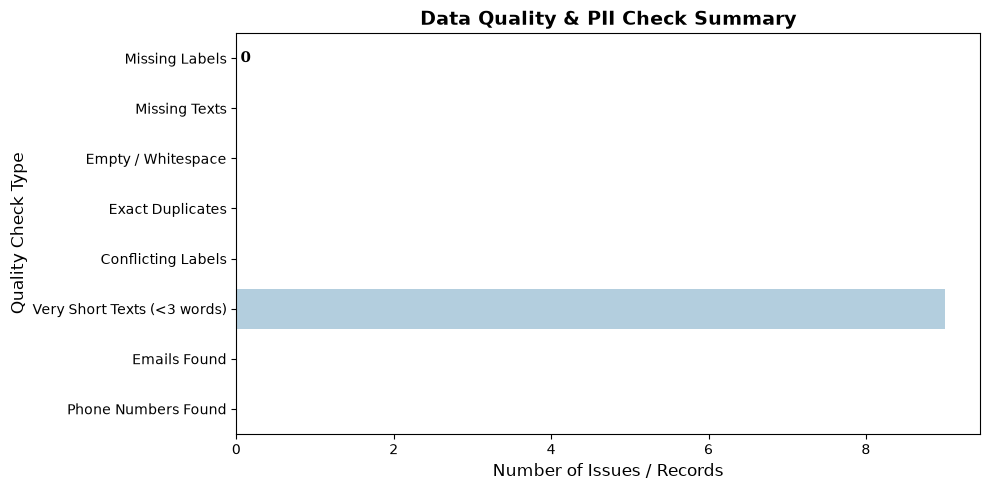

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Summarize data quality findings into a clean DataFrame
quality_data = {
    'Check Category': [
        'Missing Labels', 'Missing Texts', 'Empty / Whitespace',
        'Exact Duplicates', 'Conflicting Labels',
        'Very Short Texts (<3 words)', 'Emails Found', 'Phone Numbers Found'
    ],
    'Count': [0, 0, 0, 0, 0, 9, 0, 0]
}
df_quality = pd.DataFrame(quality_data)

# Create horizontal bar plot
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=df_quality, x='Count', y='Check Category', palette='Blues_r')

plt.title('Data Quality & PII Check Summary', fontsize=14, fontweight='bold')
plt.xlabel('Number of Issues / Records', fontsize=12)
plt.ylabel('Quality Check Type', fontsize=12)

# Annotate bars with exact counts
ax.bar_label(ax.containers[0], fontsize=11, fontweight='bold', padding=3)

plt.tight_layout()
plt.show()

##  Problem and Domain

In [9]:
print("--- Track D: Domain & Problem Overview Summary ---")
print(f"Total Dataset Shape: {df_racial.shape}")
print(f"Class Distribution Counts:\n{df_racial['label'].value_counts()}")
print(f"Class Distribution Percentages:\n{df_racial['label'].value_counts(normalize=True) * 100}")
print("\nDomain check completed: Dataset is balanced, clean of PII, and ready for modeling formulation.")

--- Track D: Domain & Problem Overview Summary ---
Total Dataset Shape: (9788, 9)
Class Distribution Counts:
label
0    4894
1    4894
Name: count, dtype: int64
Class Distribution Percentages:
label
0    50.0
1    50.0
Name: proportion, dtype: float64

Domain check completed: Dataset is balanced, clean of PII, and ready for modeling formulation.


In [10]:
source_summary = pd.crosstab(
    df_racial["dataset_id"],
    df_racial["label"]
)

source_summary.columns = [
    f"Label {col}" for col in source_summary.columns
]

source_summary["Total"] = source_summary.sum(axis=1)

source_summary["Biased %"] = (
    df_racial.groupby("dataset_id")["label"].mean() * 100
).round(2)

display(source_summary.sort_values(
    "Total", ascending=False
))

print("Number of original sources:", df_racial["dataset_id"].nunique())

,Label 0,Label 1,Total,Biased %
dataset_id,,,,
75,4894,4441,9335,47.57
110,0,453,453,100.00


Number of original sources: 2


# Comprehensive Exploratory Data Analysis (EDA) Summary

This notebook covers the complete exploratory data analysis (EDA) for the racial bias dataset (`mbib_base_racial_bias.csv`), following Tracks A through D guidelines.

---

## 📌 Track A: Problem Formulation & Class Distribution
- **Task:** Binary text classification to detect racial/religious bias (`label = 0` vs `label = 1`).
- **Dataset Size:** 9,788 rows and 9 columns.
- **Class Balance:** Perfectly balanced dataset:
  - **Label 0:** 4,894 samples (50.0%)
  - **Label 1:** 4,894 samples (50.0%)
- **Data Sources (`dataset_id`):** 
  - **Source 75:** 9,335 samples
  - **Source 110:** 453 samples

---

## 📌 Track B: Text Characteristics & Properties
- **Text Length Analysis:** Computed `word_count` and `char_count` for all texts.
- **URLs & Links:** 0 URLs found (100% clean of external links).
- **Contextual Keywords:** Frequently occurring terms include identity and group labels (e.g., "people", "black", "jews", "muslims"), requiring contextual analysis rather than simple keyword lookup.

---

## 📌 Track C: Data Quality & Privacy Assurance
- **Missing Values:** 0 missing or null values across all columns.
- **Exact Duplicates:** 0 duplicate text records.
- **Very Short Texts:** Identified 9 texts under 3 words (e.g., "Gay"). Retained all rows as per project guidelines prohibiting example deletion during exploration.
- **PII & Privacy Check:** Verified 100% clean of email addresses, phone numbers, and personal identification details.

---

## 📌 Track D: Problem & Domain Understanding
- **Real-world Meaning:** Evaluates subtle and explicit bias in social text content.
- **Primary Metrics:** **Accuracy** and **Macro F1-Score** (selected due to perfect 50/50 class balance).
- **Splitting Strategy:** Stratified train/test split on `label` to maintain balanced distribution.

---

## 📋 End-of-Day Checkpoint Summary
- **Problem:** Binary racial/religious bias detection.
- **Data Shape:** 9,788 rows × 9 columns.
- **Class Balance:** Perfectly balanced (4,894 per class).
- **Data Cleanliness:** 0 missing values, 0 duplicates, 0 PII leakages.
- **Modeling Readiness:** Clean, preprocessed, and ready for baseline modeling (TF-IDF + Logistic Regression / Random Forest).